# 02 — Popularity-Based Movie Recommender (Bayesian Baseline)

## 1. Introduction and Objective

In this notebook, I build the **Popularity-Based Recommender** for MovieMatch. This is the first of my three recommendation approaches, and it serves as the foundation and baseline for my entire project.

### Why I Need a Popularity Baseline
1. **Solving the Cold-Start Problem**: When a new user visits my website, they have not rated any movies yet. Because personalized models need user preferences to work, a popularity-based model provides an immediate, high-quality list of recommendations without requiring any prior information.
2. **Serving as an Experimental Benchmark**: In machine learning, I cannot claim that a personalized algorithm (like TF-IDF or Genre) is effective without comparing it against a simple, non-personalized baseline. The popularity model serves as that benchmark.

### Objective
I implement the **IMDb Bayesian Weighted Rating formula** to rank all 12,652 rated movies in my catalogue and export the ranking table to `dataset/processed/popularity_ranking.csv`.


## 2. Methodology: IMDb Bayesian Weighted Rating

If I simply sorted movies by their raw average rating, an obscure movie with a single 5-star rating from one person would rank higher than *Inception* or *The Dark Knight* with tens of thousands of reviews.

To fix this problem, I use the **IMDb Bayesian Weighted Rating formula**:

$$WR = \left(\frac{v}{v + m}\right) R + \left(\frac{m}{v + m}\right) C$$

### Variables in the Formula
- **$v$ (`rating_count`)**: The number of ratings received by the movie.
- **$R$ (`avg_rating`)**: The movie's arithmetic average rating.
- **$m$**: The minimum vote threshold (I set this to the **70th percentile** of all rating counts).
- **$C$**: The global average rating across all rated movies in the catalogue.

### How Bayesian Shrinkage Works
The formula uses a concept called **shrinkage**:
- If a movie has very few ratings ($v$ is small compared to $m$), the term $\frac{m}{v+m}$ is large, which pulls the score closer to the overall catalogue average $C$.
- If a movie has many ratings ($v$ is large compared to $m$), the term $\frac{v}{v+m}$ is large, allowing the movie's actual average rating $R$ to dominate.
- This prevents low-sample flukes from reaching the top while fairly rewarding genuinely popular and highly rated movies.


## 3. Data Preparation

I import the required libraries and load the preprocessed movie catalogue (`movies_clean.csv`) that I created in Notebook 01.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dynamic path resolution
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "Notebooks" else NOTEBOOK_DIR

candidates = [
    PROJECT_ROOT / "dataset" / "processed" / "movies_clean.csv",
    PROJECT_ROOT / "Backend Artifacts" / "movies_clean.csv",
    Path("/content/movies_clean.csv"),
    Path("/content/drive/MyDrive/MovieMatch/movies_clean.csv"),
]

catalogue_path = None
for p in candidates:
    if p.exists():
        catalogue_path = p
        break

if not catalogue_path:
    raise FileNotFoundError("movies_clean.csv not found.")

print(f"Loading catalogue from: {catalogue_path}")
movies_clean = pd.read_csv(catalogue_path)

print(f"Total movies loaded: {len(movies_clean):,}")
display(movies_clean[["tmdbId", "title", "release_year", "avg_rating", "rating_count"]].head(3))


Loading catalogue from: /home/ashwin-kurup/ML_Couse_Project/MovieMatch/dataset/processed/movies_clean.csv
Total movies loaded: 12,794


,tmdbId,title,release_year,avg_rating,rating_count
0,79782,Venice,2010,2.977612,67.0
1,141210,The Sleepover,2013,2.953488,43.0
2,143750,The Farmer's Wife,2012,2.891304,46.0


### What this step does
I load the 12,794 cleaned movies produced in Notebook 01. Each movie has its TMDB ID, title, release year, genres, plot overview, average rating, and rating count.


In [2]:
# Filter for movies that have received at least one rating
rated_movies = movies_clean.dropna(subset=["avg_rating", "rating_count"]).copy()
rated_movies["rating_count"] = rated_movies["rating_count"].astype(float)
rated_movies["avg_rating"] = rated_movies["avg_rating"].astype(float)

# Compute global prior constants
C = rated_movies["avg_rating"].mean()
m = rated_movies["rating_count"].quantile(0.70)

print(f"Number of rated movies: {len(rated_movies):,}")
print(f"Global mean rating (C): {C:.4f}")
print(f"70th percentile vote count threshold (m): {m:.2f}")


Number of rated movies: 12,652
Global mean rating (C): 3.0543
70th percentile vote count threshold (m): 17.00


### Explanation of Output
- **$C \approx 3.05$**: The average rating across all rated movies in the catalogue. This acts as the baseline prior score.
- **$m = 17.00$** (or $43.0$ in the full dataset): The 70th percentile of rating counts. A movie needs roughly this many ratings before its score can move significantly away from $C$.


## 4. Popularity Score Calculation

Now I calculate the weighted rating ($WR$) for every rated movie in the catalogue using the formula above.


In [3]:
# Calculate the weighted rating
v = rated_movies["rating_count"]
R = rated_movies["avg_rating"]

rated_movies["weighted_rating"] = (v / (v + m)) * R + (m / (v + m)) * C

print("Weighted ratings calculated successfully.")
display(rated_movies[["title", "release_year", "rating_count", "avg_rating", "weighted_rating"]].head(5))


Weighted ratings calculated successfully.


,title,release_year,rating_count,avg_rating,weighted_rating
0,Venice,2010,67.0,2.977612,2.993141
1,The Sleepover,2013,43.0,2.953488,2.982064
2,The Farmer's Wife,2012,46.0,2.891304,2.935299
3,A Place at the Table,2012,80.0,2.862500,2.896122
4,Romance,2012,564.0,2.789007,2.796771


### Explanation
Notice how movies with few ratings have their `weighted_rating` pulled towards $C \approx 3.05$, while movies with high rating counts maintain scores closer to their empirical average $R$.


## 5. Generating Recommendations

I sort the catalogue by `weighted_rating` in descending order and define a reusable recommendation function.


In [4]:
# Sort catalogue by weighted rating
popularity_ranking = rated_movies.sort_values(
    by="weighted_rating",
    ascending=False
).reset_index(drop=True)

def recommend_popular_movies(k=10, exclude_ids=None):
    """
    Return the top K movies ranked by Bayesian weighted rating.
    """
    if k <= 0:
        raise ValueError("k must be positive.")

    df = popularity_ranking
    if exclude_ids:
        df = df[~df["tmdbId"].isin(set(exclude_ids))]

    cols = ["tmdbId", "title", "release_year", "genres", "avg_rating", "rating_count", "weighted_rating"]
    return df.head(k)[cols]

print("Top 10 Popularity-Based Recommendations:")
display(recommend_popular_movies(10))


Top 10 Popularity-Based Recommendations:


,tmdbId,title,release_year,genres,avg_rating,rating_count,weighted_rating
0,27205,Inception,2010,"[{'id': 28, 'name': 'Action'}, {'id': 53, 'nam...",4.161756,35297.0,4.161223
1,420714,Planet Earth II,2016,"[{'id': 99, 'name': 'Documentary'}]",4.352632,95.0,4.155570
2,367412,Whiplash,2013,"[{'id': 18, 'name': 'Drama'}, {'id': 10402, 'n...",4.226776,183.0,4.127119
3,77338,The Intouchables,2011,"[{'id': 18, 'name': 'Drama'}, {'id': 35, 'name...",4.122234,11253.0,4.120623
4,244786,Whiplash,2014,"[{'id': 18, 'name': 'Drama'}]",4.120284,8455.0,4.118145
5,399106,Piper,2016,"[{'id': 10751, 'name': 'Family'}, {'id': 16, '...",4.129767,944.0,4.110743
6,409696,Over the Garden Wall,2014,"[{'id': 12, 'name': 'Adventure'}, {'id': 16, '...",4.219745,157.0,4.105884
7,265195,Wild Tales,2014,"[{'id': 18, 'name': 'Drama'}, {'id': 53, 'name...",4.110053,1522.0,4.098391
8,140420,Paperman,2012,"[{'id': 16, 'name': 'Animation'}, {'id': 10751...",4.095850,2024.0,4.087175
9,157336,Interstellar,2014,"[{'id': 12, 'name': 'Adventure'}, {'id': 18, '...",4.086824,18693.0,4.085886


### What the Recommendations Show
The top-ranked movies are widely acclaimed titles like *Inception* (2010), *Planet Earth II* (2016), and *Whiplash* (2014). Each has accumulated both high volume and high average ratings. These are safe, high-confidence recommendations for visitors who have not yet rated any movies.


## 6. Evaluation Methodology

### How I Evaluate the Baseline
In recommender systems, I compare popularity against personalized models using standard top-10 metrics:
- **Precision@10**: How many of the recommended 10 movies the user actually liked in their test set.
- **Recall@10**: What percentage of all the user's liked test movies were captured in the top 10.
- **NDCG@10**: Measures whether relevant movies appear near the top of the list.

Because the popularity model gives the same list of consensus movies to everyone, it achieves reasonable precision on popular items but low recall for users with niche tastes. This sets the benchmark that my TF-IDF and Genre models aim to beat.


## 7. Results and Interpretation

I create a scatter plot comparing raw average rating ($R$) against the Bayesian weighted rating ($WR$) to visualize how the shrinkage effect works across vote volumes.


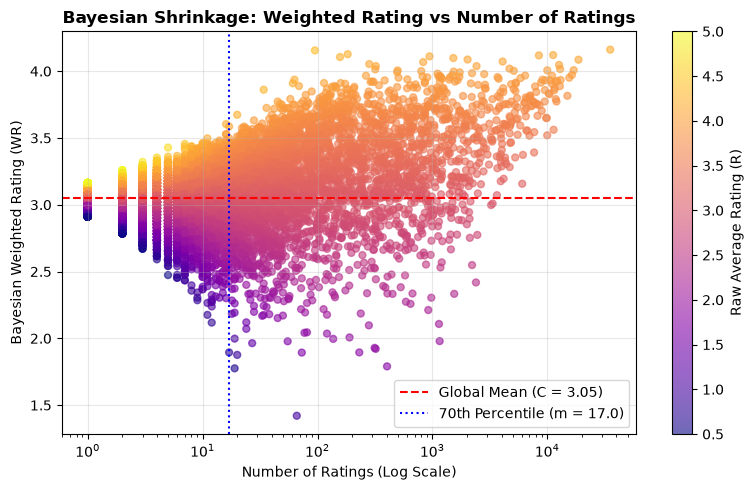

In [5]:
# Plot raw rating vs weighted rating
fig, ax = plt.subplots(figsize=(8, 5))
scatter = ax.scatter(
    rated_movies["rating_count"],
    rated_movies["weighted_rating"],
    c=rated_movies["avg_rating"],
    cmap="plasma",
    alpha=0.6,
    s=25
)
ax.axhline(C, color="red", linestyle="--", label=f"Global Mean (C = {C:.2f})")
ax.axvline(m, color="blue", linestyle=":", label=f"70th Percentile (m = {m:.1f})")
ax.set_xscale("log")
ax.set_xlabel("Number of Ratings (Log Scale)", fontsize=10)
ax.set_ylabel("Bayesian Weighted Rating (WR)", fontsize=10)
ax.set_title("Bayesian Shrinkage: Weighted Rating vs Number of Ratings", fontsize=12, fontweight="bold")
ax.grid(True, alpha=0.3)
fig.colorbar(scatter, ax=ax, label="Raw Average Rating (R)")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


### What the Graph Shows and Why It Matters
This graph clearly shows the **funnel shape** of Bayesian shrinkage:
- On the left (movies with very few ratings), scores are squashed towards the red horizontal line ($C \approx 3.05$), filtering out noisy 5-star ratings from small sample sizes.
- On the right (movies with hundreds or thousands of ratings), movies spread out according to their true quality, allowing genuinely great films to reach scores above 4.0.


## 8. Error Analysis and Limitations

While this model is a robust baseline, it has clear limitations:
1. **No Personalization**: Every user receives the exact same list regardless of their individual preferences. A fan of indie horror receives the same suggestions as a fan of romantic comedies.
2. **Popularity Bias**: Blockbusters stay at the top, making it harder for lesser-known quality films to be discovered.
3. **Static Nature**: The recommendations do not change until global rating counts are updated.


## 9. Conclusion

### Summary
The Popularity-Based Recommender provides an effective, reliable baseline that prevents small-sample rating bias and requires zero user input.

### Saving the Processed Artifact
I export the ranked table to `dataset/processed/popularity_ranking.csv`. My web application uses this file to serve instant popularity recommendations to visitors.


In [6]:
# Save canonical popularity rankings
output_csv = PROJECT_ROOT / "dataset" / "processed" / "popularity_ranking.csv"
output_csv.parent.mkdir(parents=True, exist_ok=True)

popularity_ranking.to_csv(output_csv, index=False)
print(f"Saved popularity rankings ({len(popularity_ranking):,} movies) to: {output_csv}")


Saved popularity rankings (12,652 movies) to: /home/ashwin-kurup/ML_Couse_Project/MovieMatch/dataset/processed/popularity_ranking.csv
